<a href="https://colab.research.google.com/github/thiagosilva33f-ux/Analise-de-banco-de-Dados-aberto-/blob/main/C%C3%B3pia_de_Rlticole.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

100%|██████████| 2.09k/2.09k [00:00<00:00, 1.48MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1


In [ ]:
import os
import pandas as pd

# List files in the downloaded dataset directory
files = os.listdir(path)
print("Arquivos no diretório:", files)

# Find the CSV file
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório do dataset.")

Arquivos no diretório: ['Ice Cream.csv']


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


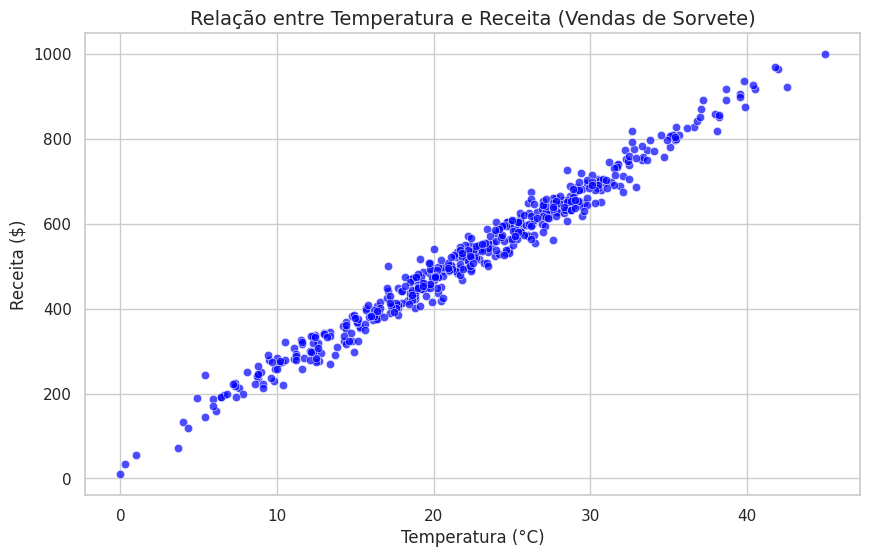

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Temperature', y='Revenue', color='blue', alpha=0.7)

# Adicionar títulos e rótulos
plt.title('Relação entre Temperatura e Receita (Vendas de Sorvete)', fontsize=14)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita ($)', fontsize=12)

# Exibir o gráfico
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numpy as np

# Definindo variáveis independente (X) e dependente (y)
X = df[['Temperature']]
y = df['Revenue']

# Dividindo os dados em conjuntos de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializando e treinando o modelo de regressão linear
model = LinearRegression()
model.fit(X_train, y_train)

# Fazendo previsões no conjunto de teste
y_pred = model.predict(X_test)

# Avaliando o modelo
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)

print("--- Métricas de Avaliação ---")
print(f"Erro Médio Absoluto (MAE): {mae:.2f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse:.2f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Coeficiente (Inclinação): {model.coef_[0]:.2f}")
print(f"Intercepto: {model.intercept_:.2f}")

--- Métricas de Avaliação ---
Erro Médio Absoluto (MAE): 19.20
Erro Quadrático Médio (MSE): 652.49
Raiz do Erro Quadrático Médio (RMSE): 25.54
Coeficiente de Determinação (R²): 0.9772
Coeficiente (Inclinação): 21.38
Intercepto: 46.18


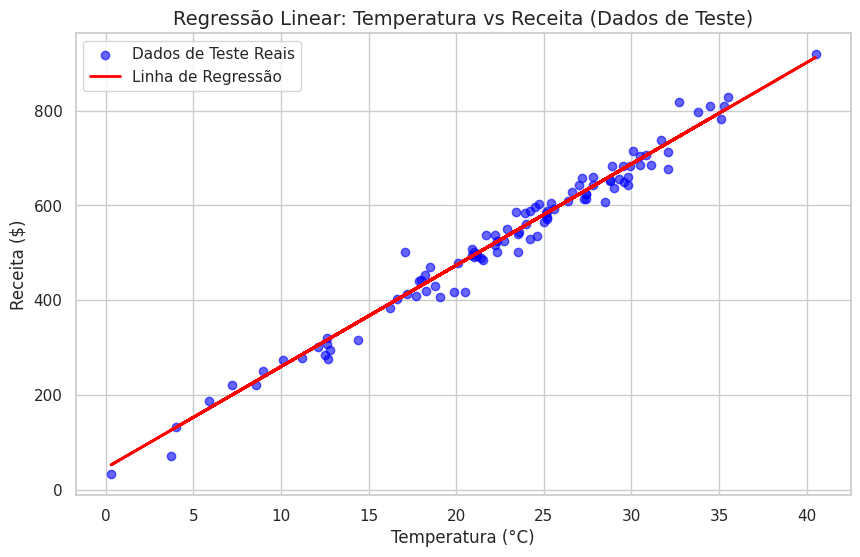

In [ ]:
# Plotando a reta de regressão junto com os dados reais
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dados de Teste Reais')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Linha de Regressão')
plt.title('Regressão Linear: Temperatura vs Receita (Dados de Teste)', fontsize=14)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita ($)', fontsize=12)
plt.legend()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numpy as np

# Ajustando o modelo de regressão linear simples utilizando os dados
X = df[['Temperature']]
y = df['Revenue']

model = LinearRegression()
model.fit(X, y)

# Exibindo os coeficientes obtidos
print("=== Modelo de Regressão Linear Simples ===")
print(f"Coeficiente Angular (Inclinação): {model.coef_[0]:.4f}")
print(f"Coeficiente Linear (Intercepto): {model.intercept_:.4f}")
print(f"Equação estimada: Receita = {model.coef_[0]:.2f} * Temperatura + {model.intercept_:.2f}")

=== Modelo de Regressão Linear Simples ===
Coeficiente Angular (Inclinação): 21.4420
Coeficiente Linear (Intercepto): 44.2968
Equação estimada: Receita = 21.44 * Temperatura + 44.30
